# Heat stress indices

Air temperature alone does not give an accurate measure of heat stress. Humidity decreases the heat that the body loses by sweat. Wind and solar radiation also change the heat load. Thus, two days with the same temperature can have a different physiological risk.

This notebook calculates the heat-stress indices in `varunayan`, compares them, and
gets them from ERA5 in one call.

| Index | Inputs | Primary use |
|-------|--------|-------------|
| Temperature | T | baseline |
| Wet bulb (Stull 2011) | T + humidity | physiological limit |
| Heat index (NWS Rothfusz) | T + RH | public weather alerts |
| WBGT (BoM closed form) | T + humidity | workplace safety |
| UTCI (Bröde 2012) | T + Tmrt + wind + humidity | climate and comfort research |
| Humidex | T + dewpoint | Canadian weather |

In [1]:
import numpy as np
import pandas as pd

import varunayan as v

✓ CDS API configuration is already set up and valid.


## The indices on a controlled grid

This section changes the air temperature at three fixed relative humidity levels.
`dewpoint_from_relative_humidity` gives the dewpoint for each pair. `calc_heat_indices`
then gives wet bulb, heat index, WBGT and humidex in one DataFrame. UTCI uses a wind
speed of 2 m/s. The UTCI polynomial is valid only up to a vapor pressure of 5 kPa
(approximately 34 °C at 90 % RH). Above this limit, `utci` extrapolates the
polynomial, so this section stops at 40 °C.

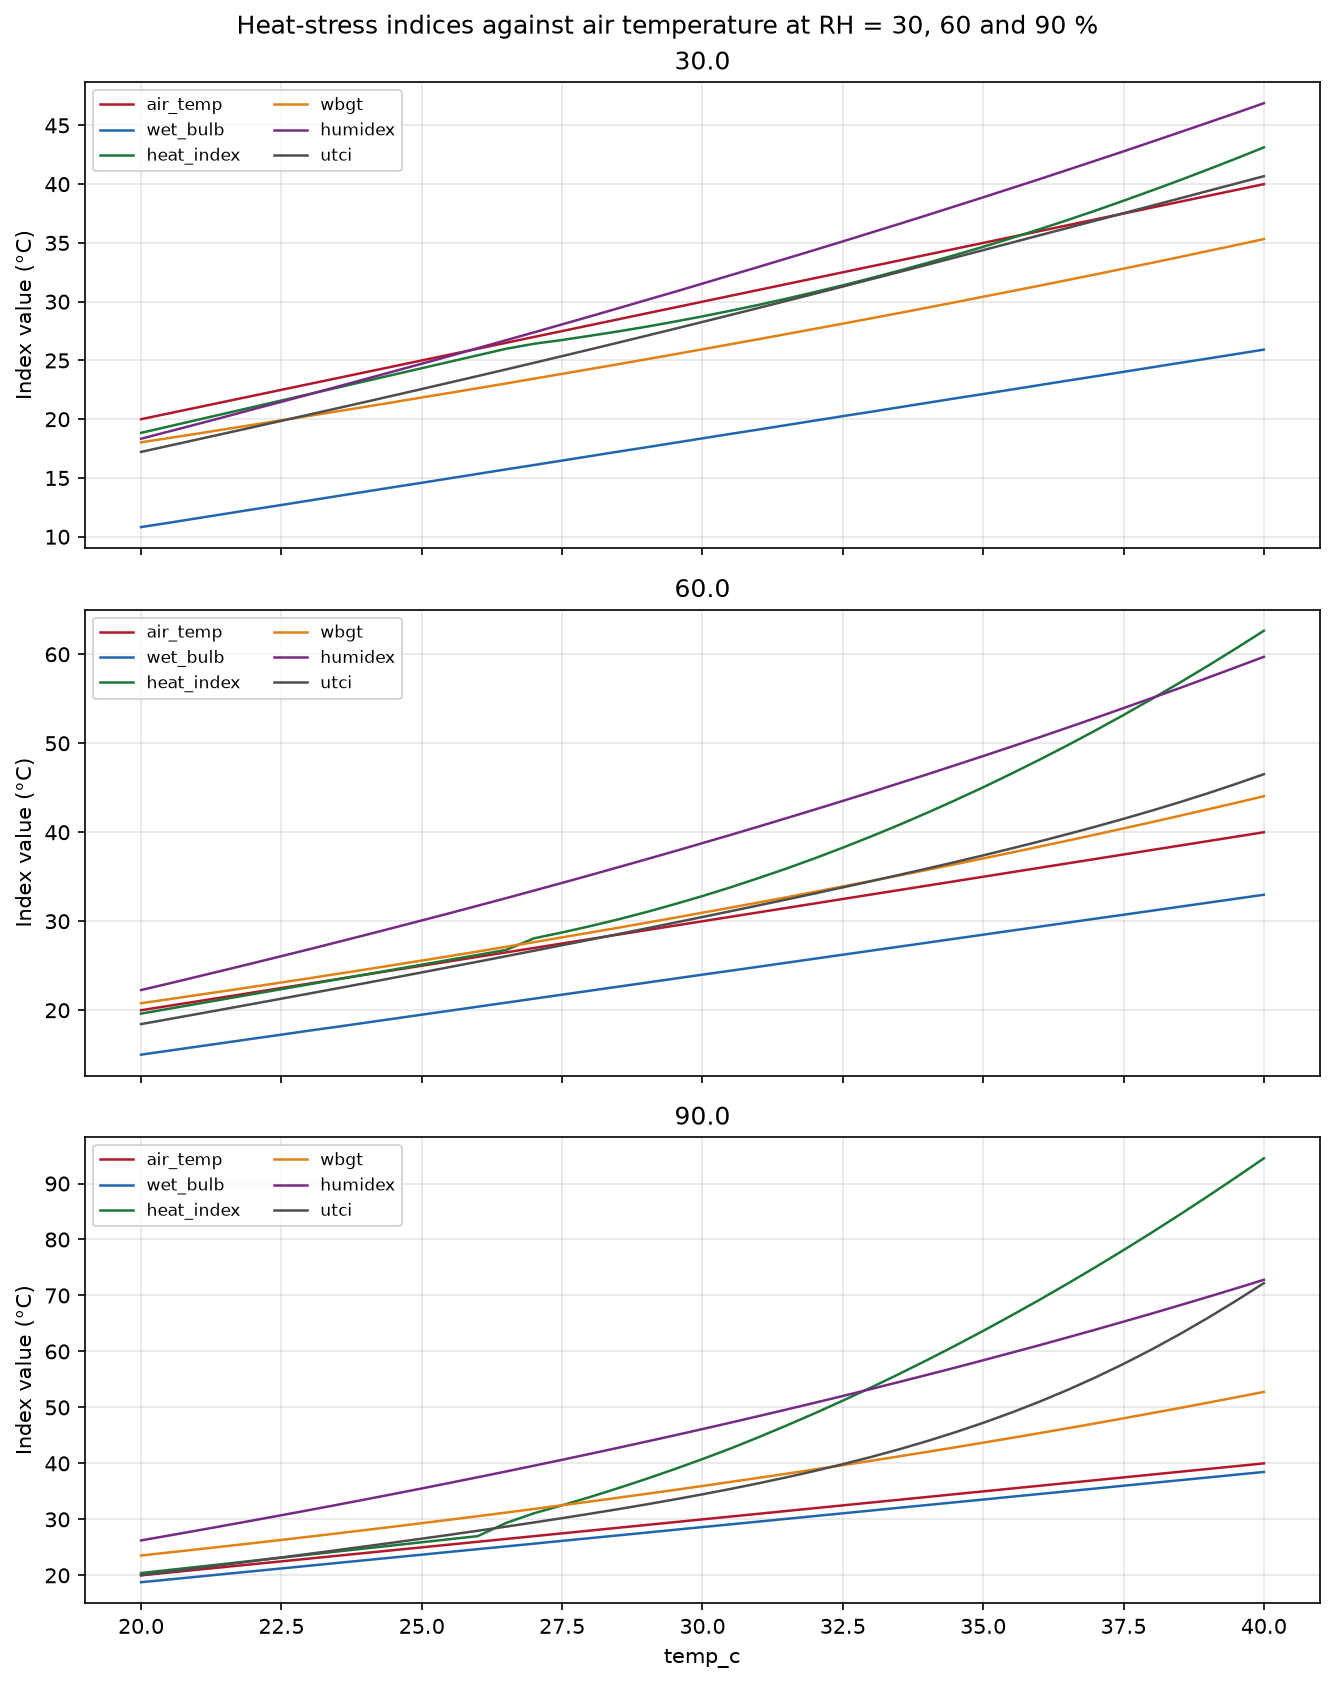

In [2]:
grid = pd.MultiIndex.from_product(
    [[30, 60, 90], np.arange(20, 40.5, 0.5)], names=["rh", "temp_c"]
).to_frame(index=False)
indices = v.calc_heat_indices(
    grid.temp_c, v.dewpoint_from_relative_humidity(grid.temp_c, grid.rh)
).assign(
    air_temp=lambda d: d.temp_c, utci=lambda d: v.utci(d.temp_c, 2.0, d.dewpoint_c)
)
long = indices.melt(
    id_vars=["temp_c", "rh"],
    value_vars=["air_temp", "wet_bulb", "heat_index", "wbgt", "humidex", "utci"],
    var_name="index",
)
v.plot_series(
    long,
    x="temp_c",
    y="value",
    by="index",
    facet="rh",
    ylabel="Index value (°C)",
    title="Heat-stress indices against air temperature at RH = 30, 60 and 90 %",
)

- The wet bulb temperature is always below the air temperature, because water evaporates.
- The heat index and humidex increase above the air temperature when the humidity increases.
- At low RH, the heat index is below the air temperature. Dry heat feels less severe
  than the thermometer value.
- UTCI and WBGT put humidity (and, for UTCI, wind) into one effective temperature.

## Risk categories

Each index has a scale of risk categories: the NWS heat-index categories
(80/90/103/124 °F), the NWS/OSHA WBGT flag conditions (78/82/85/88 °F) and the
10-level UTCI assessment scale (Bröde 2012).

In [3]:
sample = v.calc_heat_indices([22, 28, 34, 40, 46], [12, 20, 26, 30, 34]).assign(
    utci=lambda d: v.utci(d.temp_c, 2.0, d.dewpoint_c)
)
sample.assign(
    hi_risk=v.heat_index_risk_category(sample.heat_index),
    wbgt_risk=v.wbgt_risk_category(sample.wbgt),
    utci_stress=v.utci_category(sample.utci),
).round(1)

,temp_c,dewpoint_c,rh,wet_bulb,heat_index,wbgt,humidex,utci,hi_risk,wbgt_risk,utci_stress
0,22.0,12.0,53.1,15.8,21.6,21.9,24.3,20.3,Normal,Low,No thermal stress
1,28.0,20.0,61.8,22.5,29.7,29.0,35.6,28.1,Caution,High,Moderate heat stress
2,34.0,26.0,63.1,28.2,43.5,36.4,47.5,36.4,Danger,Extreme,Strong heat stress
3,40.0,30.0,57.4,32.5,60.5,43.3,58.6,45.5,Extreme Danger,Extreme,Very strong heat stress
4,46.0,34.0,52.6,36.7,80.9,51.0,70.9,57.8,Extreme Danger,Extreme,Extreme heat stress


## From ERA5 in one call

`get_era5_daily_heat_index_data` downloads temperature, dewpoint and wind for a
bounding box and returns all the indices and their categories. With `solar_load=True`,
it also downloads solar radiation and uses the mean radiant temperature in UTCI. This example uses
the region around Delhi in May 2023. You need CDS API credentials (refer to the
quickstart notebook).

The daily mean temperature increases from 23 °C to 36 °C on 22 May. UTCI is above
the air temperature on most days, because the sun adds radiant load. The wet bulb
temperature stays between 18 °C and 24 °C, because the air is dry before the monsoon.
Most grid-cell days are in the "Moderate heat stress" or "Strong heat stress" UTCI
categories.

In [4]:
heat = v.get_era5_daily_heat_index_data(
    request_id="delhi_heat_may2023",
    start_date="2023-05-01",
    end_date="2023-05-31",
    north=29.0,
    south=28.0,
    east=77.75,
    west=76.75,
    solar_load=True,
)
heat.head()

STARTING ERA5 SINGLE LEVEL PROCESSING


Request ID: delhi_heat_may2023


Variables: ['2m_temperature', '2m_dewpoint_temperature', '10m_u_component_of_wind', '10m_v_component_of_wind', 'surface_solar_radiation_downwards']


Date Range: 2023-05-01 to 2023-05-31


Frequency: daily


...


First 5 rows of aggregated data:


    datetime  latitude  longitude variable         value
0 2023-05-01      28.0      76.75      d2m  1.893389e+01
1 2023-05-01      28.0      76.75     ssrd  1.739962e+07
2 2023-05-01      28.0      76.75      t2m  2.341476e+01
3 2023-05-01      28.0      76.75      u10 -1.861332e+00
4 2023-05-01      28.0      76.75      v10  2.514470e-01


ERA5 SINGLE LEVEL PROCESSING COMPLETED SUCCESSFULLY


/Users/mcclintock/github/varunayan/python/varunayan/core.py:287: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(datasets) if len(datasets) > 1 else datasets[0]
/Users/mcclintock/github/varunayan/python/varunayan/core.py:287: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(

,date,latitude,longitude,dewpoint_c,ssrd,temp_c,u10,v10,wind_speed,rh,wet_bulb,heat_index,wbgt,humidex,mrt,utci,heat_index_risk,wbgt_risk,utci_stress
0,2023-05-01,28.0,76.75,18.933888,17399616.0,23.414761,-1.861332,0.251447,1.878239,75.959360,20.266821,23.795176,25.810911,30.137298,29.374043,25.232970,Normal,Moderate,No thermal stress
1,2023-05-01,28.0,77.00,19.261850,17634816.0,23.327359,-1.967492,0.088727,1.969492,77.938321,20.448725,23.750706,25.939043,30.307989,29.369946,25.151503,Normal,Moderate,No thermal stress
2,2023-05-01,28.0,77.25,19.587859,17300736.0,23.206428,-2.049076,-0.063739,2.050067,80.117473,20.623198,23.674582,26.050294,30.448400,29.144848,25.002361,Normal,Moderate,No thermal stress
3,2023-05-01,28.0,77.50,19.634734,16298560.0,23.150438,-2.174809,-0.106219,2.177401,80.623380,20.636519,23.626203,26.044668,30.430384,28.757375,24.687929,Normal,Moderate,No thermal stress
4,2023-05-01,28.0,77.75,19.598032,15079488.0,23.153205,-2.489709,-0.112241,2.492238,80.426402,20.613062,23.624104,26.025780,30.403410,28.351333,24.091883,Normal,Moderate,No thermal stress


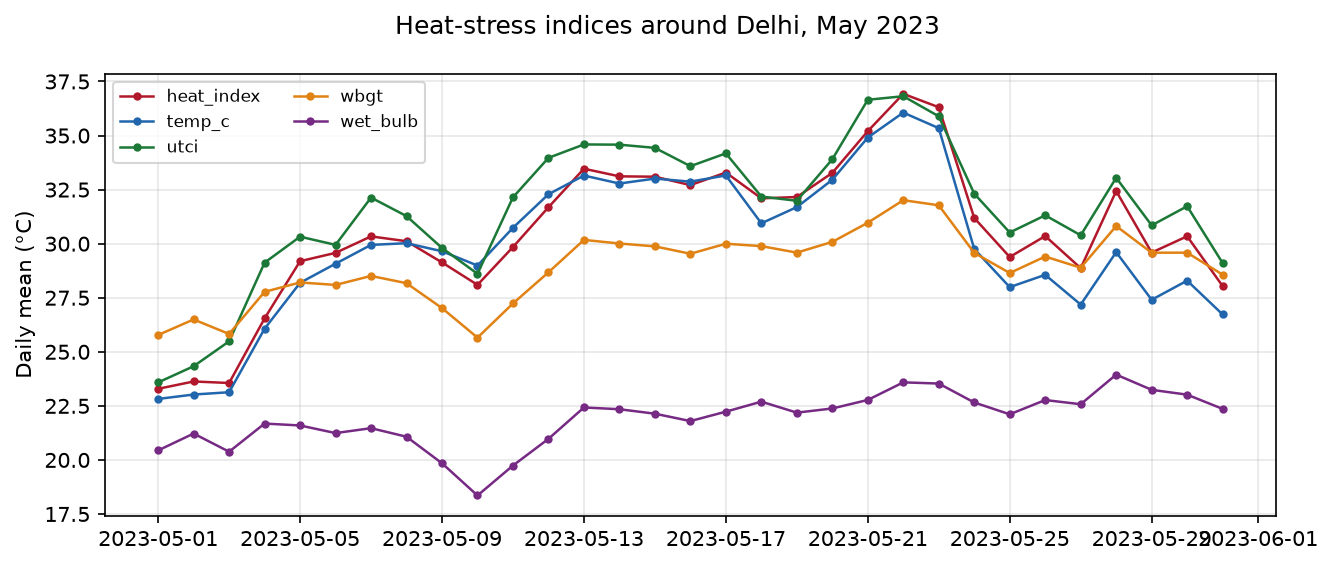

In [5]:
daily = heat.melt(
    id_vars=["date", "latitude", "longitude"],
    value_vars=["temp_c", "wet_bulb", "heat_index", "wbgt", "utci"],
    var_name="index",
)
v.plot_series(
    v.spatial_mean(daily, "value", by=["date", "index"]),
    x="date",
    y="value",
    by="index",
    ylabel="Daily mean (°C)",
    title="Heat-stress indices around Delhi, May 2023",
)

In [6]:
heat["utci_stress"].value_counts()

utci_stress
Strong heat stress         362
Moderate heat stress       345
No thermal stress           66
Very strong heat stress      2
Name: count, dtype: int64

## Solar load

`mean_radiant_temperature` (Thorsson 2007) adds the radiant load of the sun to the air
temperature. This example keeps the air temperature at 38 °C and the dewpoint at
24 °C, and increases the solar radiation from 0 to 1000 W/m².

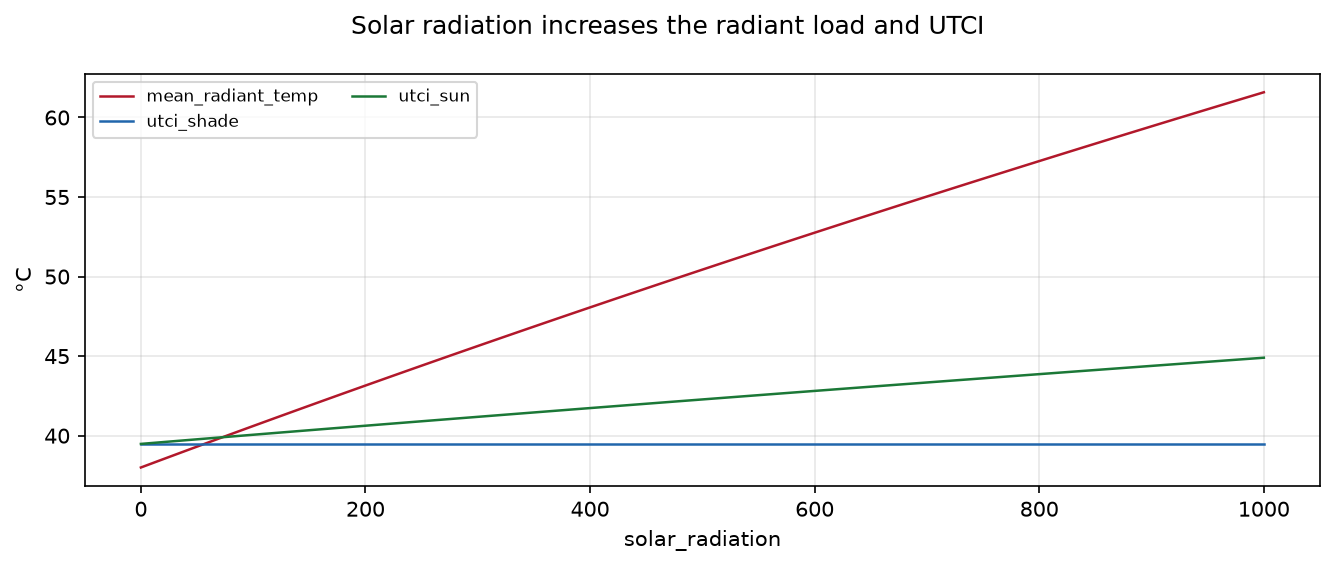

In [7]:
sun = pd.DataFrame({"solar_radiation": np.linspace(0, 1000, 51)})
sun = sun.assign(
    mean_radiant_temp=v.mean_radiant_temperature(38.0, sun.solar_radiation),
    utci_shade=v.utci(38.0, 2.0, 24.0),
    utci_sun=lambda d: v.utci(38.0, 2.0, 24.0, tmrt=d.mean_radiant_temp),
)
v.plot_series(
    sun.melt(id_vars="solar_radiation", var_name="series"),
    x="solar_radiation",
    y="value",
    by="series",
    ylabel="°C",
    title="Solar radiation increases the radiant load and UTCI",
)

## Relationship between indices

The correlation matrix of the ERA5 daily values shows that each index measures a
different part of heat stress. In this dry month, the heat index and UTCI follow the
air temperature (r = 0.95 or more). The wet bulb temperature has only a weak
correlation with the air temperature (r = 0.35), because humidity controls it. WBGT
and humidex are between the two groups.

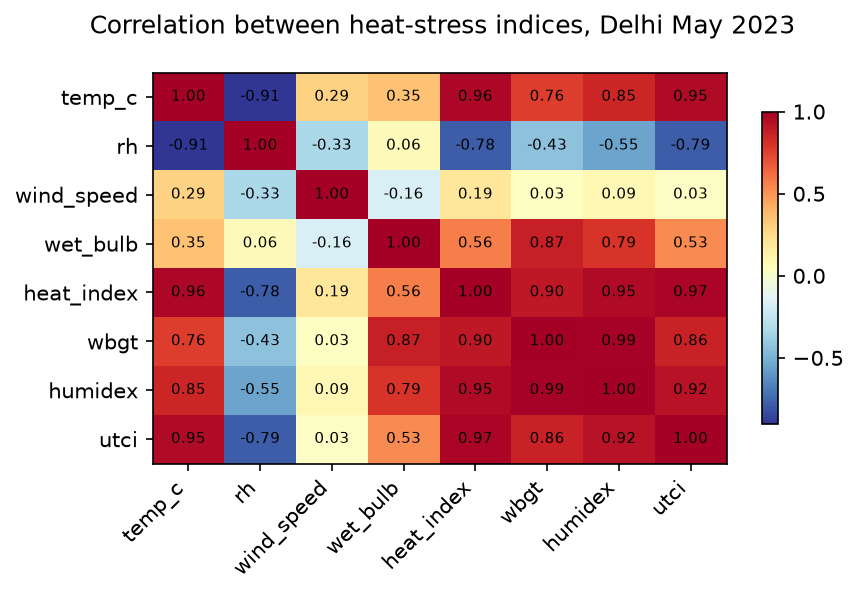

In [8]:
v.plot_heatmap(
    heat[
        [
            "temp_c",
            "rh",
            "wind_speed",
            "wet_bulb",
            "heat_index",
            "wbgt",
            "humidex",
            "utci",
        ]
    ].corr(),
    annotate=True,
    title="Correlation between heat-stress indices, Delhi May 2023",
)

## References

- Stull (2011), *J. Appl. Meteorol. Climatol.* 50:2267-2269. Wet bulb.
- Rothfusz (1990), NWS SR/SSD 90-23. Heat index.
- Bröde et al. (2012), *Int. J. Biometeorol.* 56:481-494. UTCI.
- Thorsson et al. (2007), *Int. J. Climatol.* 27:1983-1993. Mean radiant temperature.
- Masterson and Richardson (1979), Environment Canada. Humidex.
- Australian Bureau of Meteorology. WBGT approximation.